In [ ]:
# 문제1 :: "동영상을 37분 촬영하였을 때 예상되는 파일 용량은 어떻게 되는가?"
# 문제2 :: "1000의 크기 동영상을 촬영할 수 있을 때, 최대 몇 분까지 촬영할 수 있는가?"
# 문제3 :: "동영상 촬영 시간에 따라 동영상 파일 크기는 어떻게 변화하는가?"

# 선형회귀 모델의 머신러닝을 활용하여 아래의 해답을 구하여라.
#       (이때, 기존에 주어진 데이터들로 모델 학습 및 테스트를 진행하여라.)
#   1. 해당 모델의 성능 및 평균 오차값에 대해 수치 상으로 확인하여라.
#   2. 머신러닝 모델을 활용하여 문제1 및 문제2 대한 예측값을 구하여라.
#   3. 실제값-예측값 비교하는 그래프를 통해, 위 문제에 대한 해답을 구하여라.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

In [2]:
time = np.array([5, 10, 15, 20, 25, 30, 35, 40, 45, 50])                # 동영상 시간
size = np.array([118, 233, 356, 473, 588, 714, 829, 947, 1065, 1183])   # 동영상 용량

In [8]:
# * 학습용/테스트용 데이터 분리
x_train, x_test, y_train, y_test = train_test_split(
    time.reshape(-1, 1),
    size
)
# print(x_train, '\n', x_test)
# print(y_train, y_test)

# * 머신러닝 모델 생성 + 학습
md = LinearRegression()       # 모델 생성
md.fit(x_train, y_train)      # 모델 학습

LinearRegression()

In [9]:
# 1. 해당 모델의 성능 및 평균 오차값에 대해 수치 상으로 확인하여라.
sc = md.score(x_test, y_test)    # (머신러닝한테 줄 문제, 비교할 정답값)

prd = md.predict(x_test)
err = mean_absolute_error(y_test, prd)

print('성능 평가:', sc)
print('평균 오차값:', err)

성능 평가: 0.9998784390774671
평균 오차값: 2.5405405405404244


In [12]:
# 2-1. 머신러닝 모델을 활용하여 문제1에 대한 예측값을 구하여라.
# "동영상을 37분(요인) 촬영하였을 때 예상되는 파일 용량(결과)은 어떻게 되는가?"
result =  md.predict([[37]])
print('문제1 정답:', result)

# 35분 용량 :: 829 용량
# 40분 용량 :: 947 용량

문제1 정답: [875.13333333]


In [15]:
# 2-2. 머신러닝 모델을 활용하여 문제2에 대한 예측값을 구하여라.
# "1000의 크기 동영상을 촬영할 수 있을 때, 최대 몇 분까지 촬영할 수 있는가?"

test_time = np.arange(1, 51)                # [1, 2, ..., 49, 50] -> 50개의 분 단위 데이터
pred = md.predict(test_time.reshape(-1, 1)) # [1, 2, ..., 49, 50]분에 대해 예측 가능한 파일의 용량 수치
print(pred, '\n')
  # md.predict([[1, 2, ..., 49, 50]])의 값

max_time = 0
for i in test_time:     # i :: 1 -> 2 -> ... -> 49 -> 50
    result = md.predict([[i]])
      # result :: 파일 크기 예측값 조회 (21.xx -> 45.xx -> 68.xx -> ... -> 1183.xx)

    # 43분의 경우에는 if문 못 들어감 (예측값 :: 1017.xx)
    if result <= 1000:
        max_time = i    # max_time 변화 :: 0 -> 1 -> 2 -> ... -> 41 -> 42(정답)

print("문제2 정답:", max_time, "분")

[  21.38198198   45.0972973    68.81261261   92.52792793  116.24324324
  139.95855856  163.67387387  187.38918919  211.1045045   234.81981982
  258.53513514  282.25045045  305.96576577  329.68108108  353.3963964
  377.11171171  400.82702703  424.54234234  448.25765766  471.97297297
  495.68828829  519.4036036   543.11891892  566.83423423  590.54954955
  614.26486486  637.98018018  661.6954955   685.41081081  709.12612613
  732.84144144  756.55675676  780.27207207  803.98738739  827.7027027
  851.41801802  875.13333333  898.84864865  922.56396396  946.27927928
  969.99459459  993.70990991 1017.42522523 1041.14054054 1064.85585586
 1088.57117117 1112.28648649 1136.0018018  1159.71711712 1183.43243243]
문제2 정답: 42 분


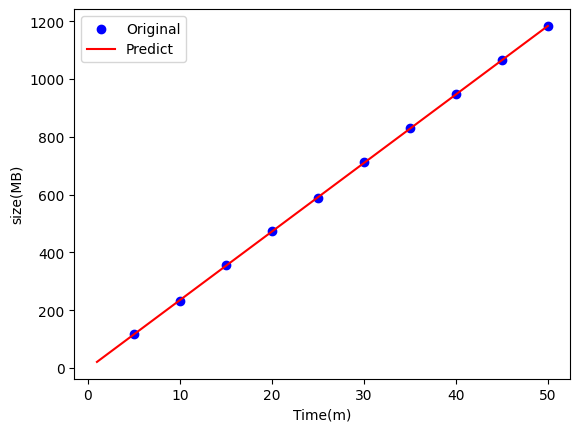

In [16]:
# 실제값-예측값 비교하는 그래프를 통해, 위 문제에 대한 해답을 구하여라.
# "동영상 촬영 시간에 따라 동영상 파일 크기는 어떻게 변화하는가?"

plt.scatter(time, size, color='blue', label='Original')

test_time = np.arange(1, 51)
pred_size = md.predict(test_time.reshape(-1, 1))
plt.plot(test_time, pred_size, color='red', label='Predict')

plt.xlabel('Time(m)')
plt.ylabel('size(MB)')
plt.legend()
plt.show()

# 오른쪽으로 갈수록, 빨간색 선이 더 높게 올라간다.
#   => "촬영 시간에 따라, 파일 용량은 비례한다."